Fit parameters:
N     = 333.7617073340002 +/- 19.031063198205366
beta  = 0.9909398311943755 +/- 0.13367899708708433
m     = 1.8936638280172753 +/- 0.2845467572554994
mu    = 0.006002418119437426 +/- 0.004803432331335041
sigma = 0.06266159325091411 +/- 0.004436367155517601


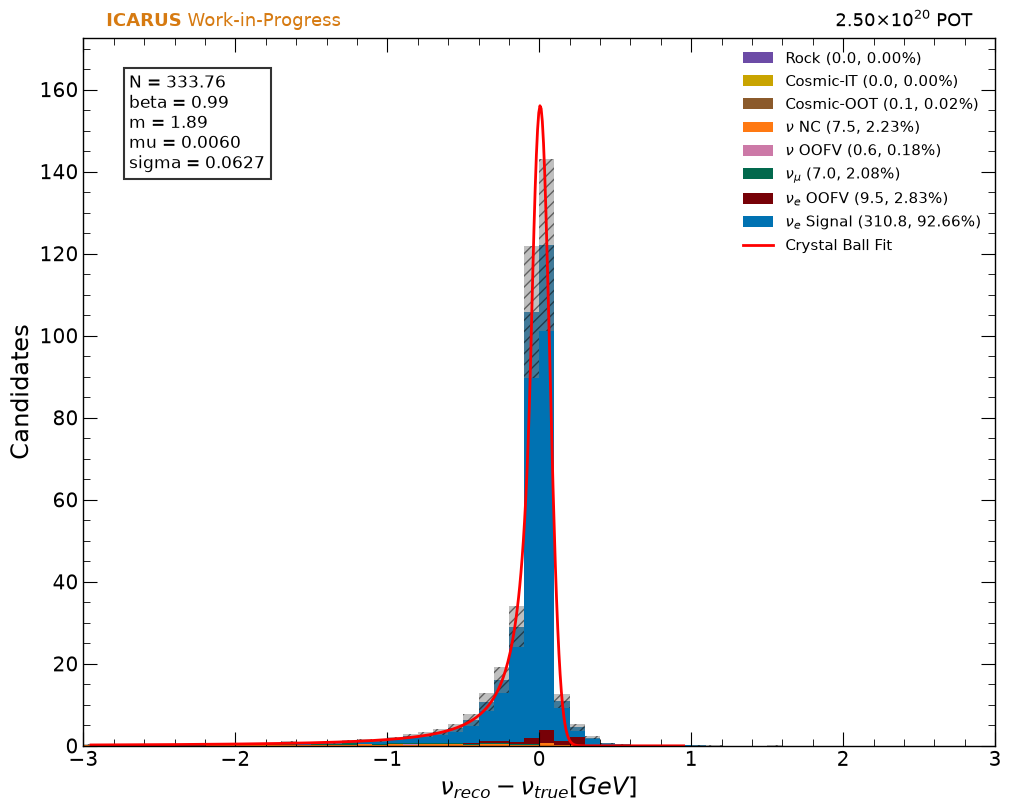

In [17]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import crystalball
from scipy.optimize import curve_fit

import uproot
import ROOT as r
import array as arr
import awkward as ak
import os

#from analysis import Analysis
import logging
import pickle
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
os.environ['MEDULLA_PLOT_DIR'] =  '/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/'
sys.path.append('/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/')
from efficiency import SpineEfficiency
from analysis import Analysis
from style import make_styled_plot, apply_style_to_plot, stamp

plt.style.use('/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/styles/nue2024.mplstyle')
# --------------------------------------------------
# Load figure
# --------------------------------------------------

with open('/nashome/m/micarrig/icarus/nuESpine/medulla/plots_v30/selection/plot_nu_diff.pkl', 'rb') as f:
    fig = pickle.load(f)

ax = fig.axes[0]

# --------------------------------------------------
# Extract histogram from matplotlib figure
# --------------------------------------------------

patches = ax.patches

# unique bin centers
all_centers = np.array([
    p.get_x() + p.get_width()/2
    for p in patches
])

all_heights = np.array([
    p.get_height()
    for p in patches
])

bin_width = patches[0].get_width()

# group identical centers
unique_centers = np.unique(all_centers)

summed_heights = []

for c in unique_centers:

    mask = np.isclose(all_centers, c)

    summed_heights.append(
        np.sum(all_heights[mask])
    )

centers = unique_centers
heights = np.array(summed_heights)

# --------------------------------------------------
# Remove empty bins
# --------------------------------------------------

mask = heights > 0
mask = mask & (centers > -3.0) & (centers < 1.0)

centers = centers[mask]
heights = heights[mask]

# --------------------------------------------------
# Crystal Ball fit function
# --------------------------------------------------

def cb_fit(x, N, beta, m, mu, sigma):

    return (
        N * bin_width
        * crystalball.pdf(
            x,
            beta,
            m,
            loc=mu,
            scale=sigma
        )
    )

# --------------------------------------------------
# Initial guesses
# --------------------------------------------------

p0 = [
    140,                 # normalization
    1.5,                             # beta
    3,                               # m
    -0.05,     # mu
    0.05                             # sigma
]

# --------------------------------------------------
# Bounds (helps stability a LOT)
# --------------------------------------------------

bounds = (
    [1, 0.5, 1.1, -1, 0.001],
    [1e9, 10, 100, 1, 10]
)

sigma_y = np.sqrt(heights)
sigma_y[sigma_y == 0] = 1

# --------------------------------------------------
# Perform fit
# --------------------------------------------------

popt, pcov = curve_fit(
    cb_fit,
    centers,
    heights,
    p0=p0,
    bounds=bounds,
    sigma=sigma_y,
    absolute_sigma=True,
    maxfev=100000
)

# --------------------------------------------------
# Draw fit
# --------------------------------------------------

xfit = np.linspace(
    np.min(centers),
    np.max(centers),
    500
)

yfit = cb_fit(xfit, *popt)

ax.plot(
    xfit,
    yfit,
    color='red',
    lw=2,
    label='Crystal Ball Fit'
)

ax.legend()
# ax.set_ylim(0, 175)

# --------------------------------------------------
# Print parameters
# --------------------------------------------------

perr = np.sqrt(np.diag(pcov))

print("Fit parameters:")
print("N     =", popt[0], "+/-", perr[0])
print("beta  =", popt[1], "+/-", perr[1])
print("m     =", popt[2], "+/-", perr[2])
print("mu    =", popt[3], "+/-", perr[3])
print("sigma =", popt[4], "+/-", perr[4])

fit_text = (
    f"N = {popt[0]:.2f}\n"
    f"beta = {popt[1]:.2f}\n"
    f"m = {popt[2]:.2f}\n"
    f"mu = {popt[3]:.4f}\n"
    f"sigma = {popt[4]:.4f}"
)

for t in fig.axes[0].texts[:]:
    t.remove()
stamp(ax, pot=2.5e20, work_in_progress=True)

ax.text(
    0.05,           # x position in axes coordinates
    0.95,           # y position
    fit_text,
    transform=ax.transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.show()

Fit parameters:
N     = 321.88845800722885 +/- 21.062979995707053
beta  = 1.0630245963251705 +/- 0.1751405907953003
m     = 1.7200155069282594 +/- 0.316279904585957
mu    = 5.976322845630413 +/- 3.136076705863009
sigma = 31.565944539605848 +/- 2.692275669832044


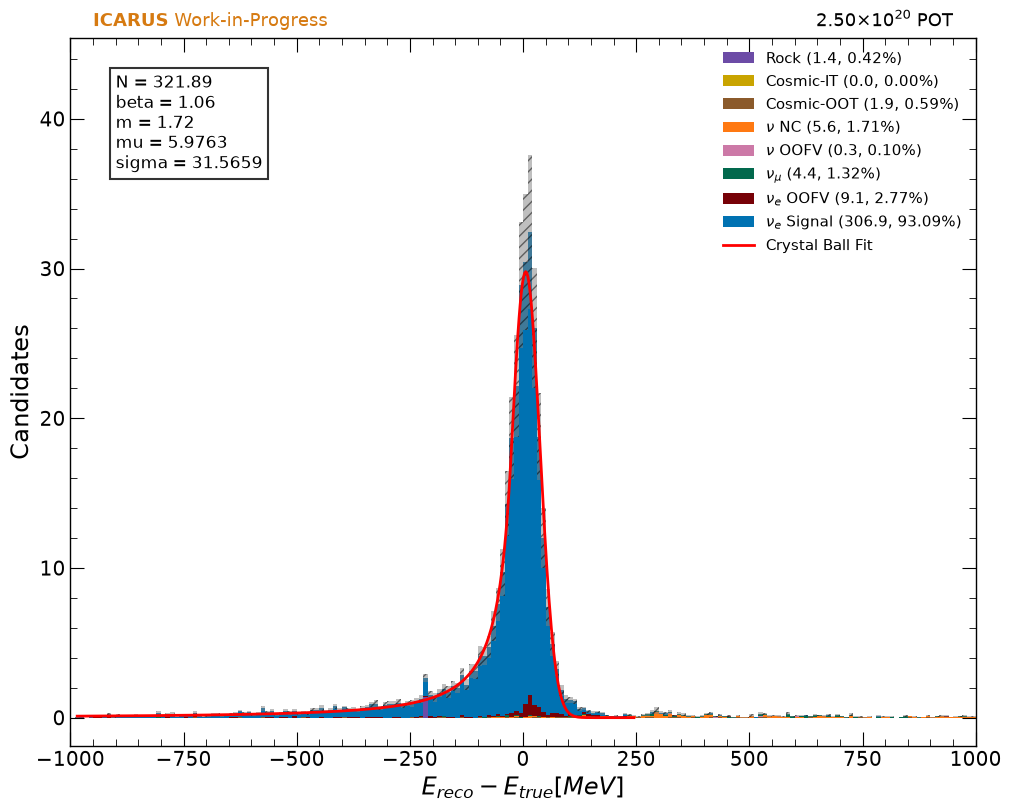

In [18]:
# --------------------------------------------------
# Load figure
# --------------------------------------------------

with open('/nashome/m/micarrig/icarus/nuESpine/medulla/plots_v30/selection/plot_ele_diff.pkl', 'rb') as f:
    fig = pickle.load(f)

ax = fig.axes[0]

# --------------------------------------------------
# Extract histogram from matplotlib figure
# --------------------------------------------------

patches = ax.patches

# unique bin centers
all_centers = np.array([
    p.get_x() + p.get_width()/2
    for p in patches
])

all_heights = np.array([
    p.get_height()
    for p in patches
])

bin_width = patches[0].get_width()

# group identical centers
unique_centers = np.unique(all_centers)

summed_heights = []

for c in unique_centers:

    mask = np.isclose(all_centers, c)

    summed_heights.append(
        np.sum(all_heights[mask])
    )

centers = unique_centers
heights = np.array(summed_heights)

# --------------------------------------------------
# Remove empty bins
# --------------------------------------------------

mask = heights > 0
mask = mask & (centers > -1000.0) & (centers < 250.0)

centers = centers[mask]
heights = heights[mask]


p0 = [
    140,                 # normalization
    1.5,                             # beta
    3,                               # m
    -50,     # mu
    100                             # sigma
]

# --------------------------------------------------
# Bounds (helps stability a LOT)
# --------------------------------------------------

bounds = (
    [1, 0.5, 1.1, -100, 0.001],
    [1e9, 10, 100, 100, 1000]
)

sigma_y = np.sqrt(heights)
sigma_y[sigma_y == 0] = 1

# --------------------------------------------------
# Perform fit
# --------------------------------------------------

popt, pcov = curve_fit(
    cb_fit,
    centers,
    heights,
    p0=p0,
    bounds=bounds,
    sigma=sigma_y,
    absolute_sigma=True,
    maxfev=100000
)

# --------------------------------------------------
# Draw fit
# --------------------------------------------------

xfit = np.linspace(
    np.min(centers),
    np.max(centers),
    500
)

yfit = cb_fit(xfit, *popt)

ax.plot(
    xfit,
    yfit,
    color='red',
    lw=2,
    label='Crystal Ball Fit'
)

ax.legend()
# ax.set_ylim(0, 175)

# --------------------------------------------------
# Print parameters
# --------------------------------------------------

perr = np.sqrt(np.diag(pcov))

print("Fit parameters:")
print("N     =", popt[0], "+/-", perr[0])
print("beta  =", popt[1], "+/-", perr[1])
print("m     =", popt[2], "+/-", perr[2])
print("mu    =", popt[3], "+/-", perr[3])
print("sigma =", popt[4], "+/-", perr[4])

fit_text = (
    f"N = {popt[0]:.2f}\n"
    f"beta = {popt[1]:.2f}\n"
    f"m = {popt[2]:.2f}\n"
    f"mu = {popt[3]:.4f}\n"
    f"sigma = {popt[4]:.4f}"
)

for t in fig.axes[0].texts[:]:
    t.remove()
stamp(ax, pot=2.5e20, work_in_progress=True)

ax.text(
    0.05,           # x position in axes coordinates
    0.95,           # y position
    fit_text,
    transform=ax.transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.show()

Fit parameters:
N     = 308.8366615776666 +/- 17.640322830246806
beta  = 1.5378479443291269 +/- 0.24610073158039164
m     = 2.1302349808484746 +/- 0.5889569488458042
mu    = -0.0005925387831630615 +/- 0.001224676899600949
sigma = 0.01833860910305461 +/- 0.0010813385789452794


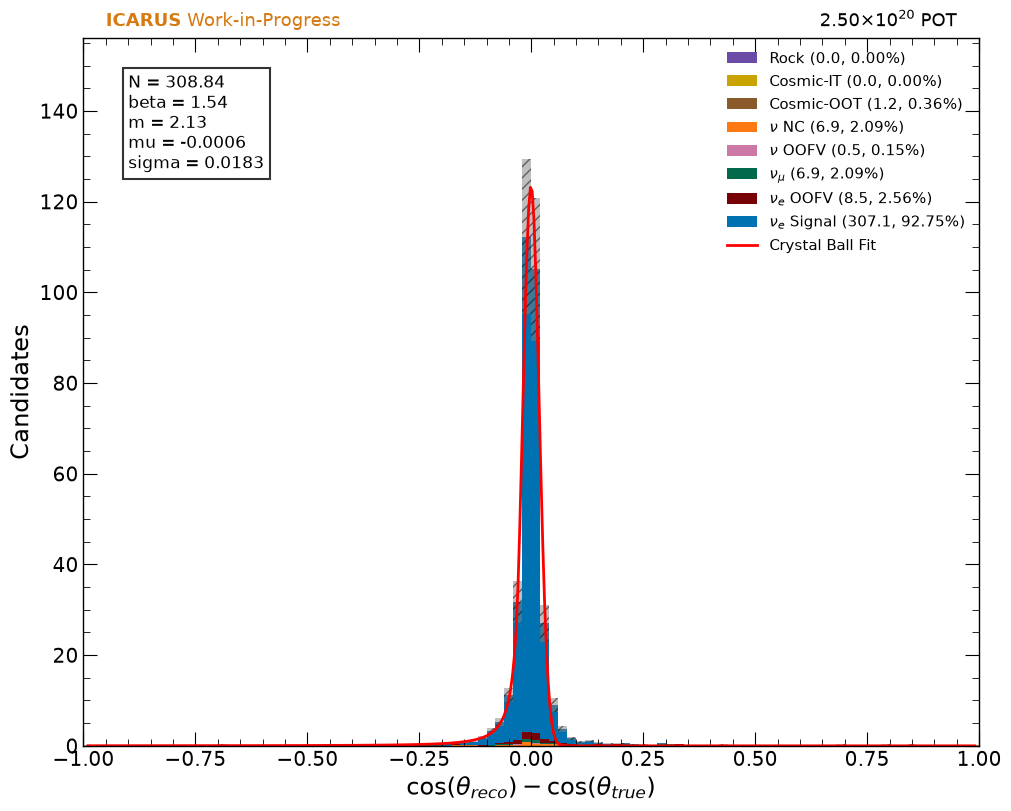

In [19]:
# --------------------------------------------------
# Load figure
# --------------------------------------------------

with open('/nashome/m/micarrig/icarus/nuESpine/medulla/plots_v30/selection/plot_angle_diff.pkl', 'rb') as f:
    fig = pickle.load(f)

ax = fig.axes[0]

# --------------------------------------------------
# Extract histogram from matplotlib figure
# --------------------------------------------------

patches = ax.patches

# unique bin centers
all_centers = np.array([
    p.get_x() + p.get_width()/2
    for p in patches
])

all_heights = np.array([
    p.get_height()
    for p in patches
])

bin_width = patches[0].get_width()

# group identical centers
unique_centers = np.unique(all_centers)

summed_heights = []

for c in unique_centers:

    mask = np.isclose(all_centers, c)

    summed_heights.append(
        np.sum(all_heights[mask])
    )

centers = unique_centers
heights = np.array(summed_heights)

# --------------------------------------------------
# Remove empty bins
# --------------------------------------------------

mask = heights > 0
mask = mask & (centers > -1000.0) & (centers < 250.0)

centers = centers[mask]
heights = heights[mask]


p0 = [
    140,                 # normalization
    1.5,                             # beta
    3,                               # m
    -50,     # mu
    100                             # sigma
]

# --------------------------------------------------
# Bounds (helps stability a LOT)
# --------------------------------------------------

bounds = (
    [1, 0.5, 1.1, -100, 0.001],
    [1e9, 10, 100, 100, 1000]
)

sigma_y = np.sqrt(heights)
sigma_y[sigma_y == 0] = 1

# --------------------------------------------------
# Perform fit
# --------------------------------------------------

popt, pcov = curve_fit(
    cb_fit,
    centers,
    heights,
    p0=p0,
    bounds=bounds,
    sigma=sigma_y,
    absolute_sigma=True,
    maxfev=100000
)

# --------------------------------------------------
# Draw fit
# --------------------------------------------------

xfit = np.linspace(
    np.min(centers),
    np.max(centers),
    500
)

yfit = cb_fit(xfit, *popt)

ax.plot(
    xfit,
    yfit,
    color='red',
    lw=2,
    label='Crystal Ball Fit'
)

ax.legend()
# ax.set_ylim(0, 175)

# --------------------------------------------------
# Print parameters
# --------------------------------------------------

perr = np.sqrt(np.diag(pcov))

print("Fit parameters:")
print("N     =", popt[0], "+/-", perr[0])
print("beta  =", popt[1], "+/-", perr[1])
print("m     =", popt[2], "+/-", perr[2])
print("mu    =", popt[3], "+/-", perr[3])
print("sigma =", popt[4], "+/-", perr[4])

fit_text = (
    f"N = {popt[0]:.2f}\n"
    f"beta = {popt[1]:.2f}\n"
    f"m = {popt[2]:.2f}\n"
    f"mu = {popt[3]:.4f}\n"
    f"sigma = {popt[4]:.4f}"
)

for t in fig.axes[0].texts[:]:
    t.remove()
stamp(ax, pot=2.5e20, work_in_progress=True)

ax.text(
    0.05,           # x position in axes coordinates
    0.95,           # y position
    fit_text,
    transform=ax.transAxes,
    fontsize=12,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)

plt.show()

/tmp/ipykernel_2896/3123605076.py:41: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


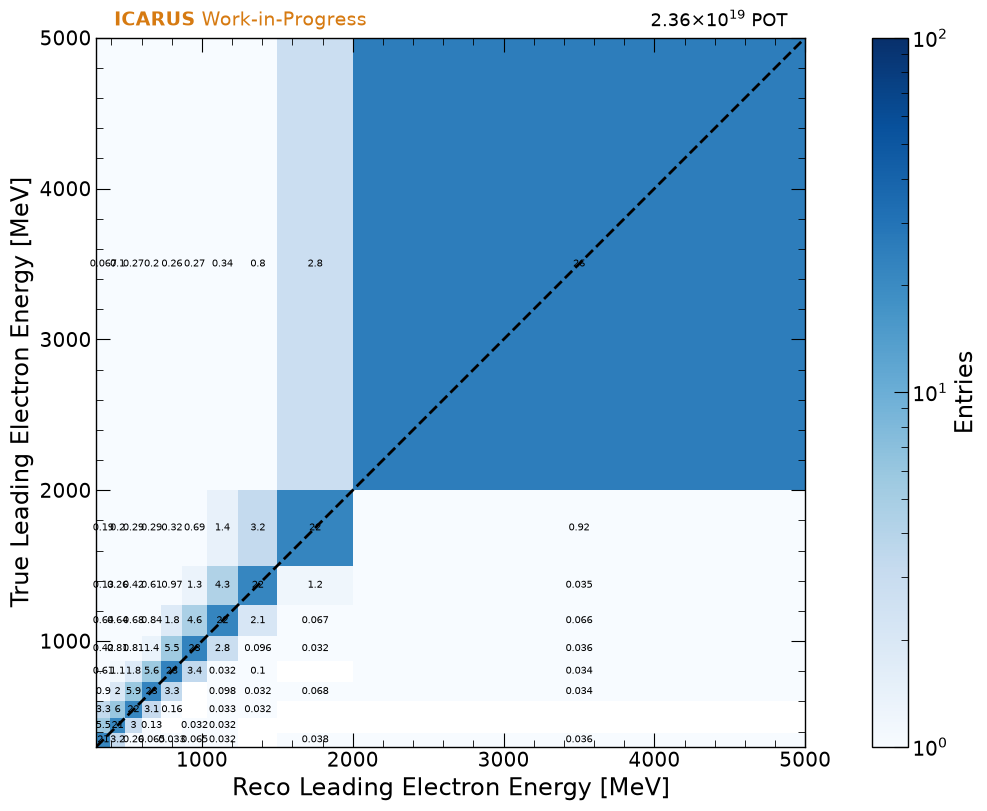

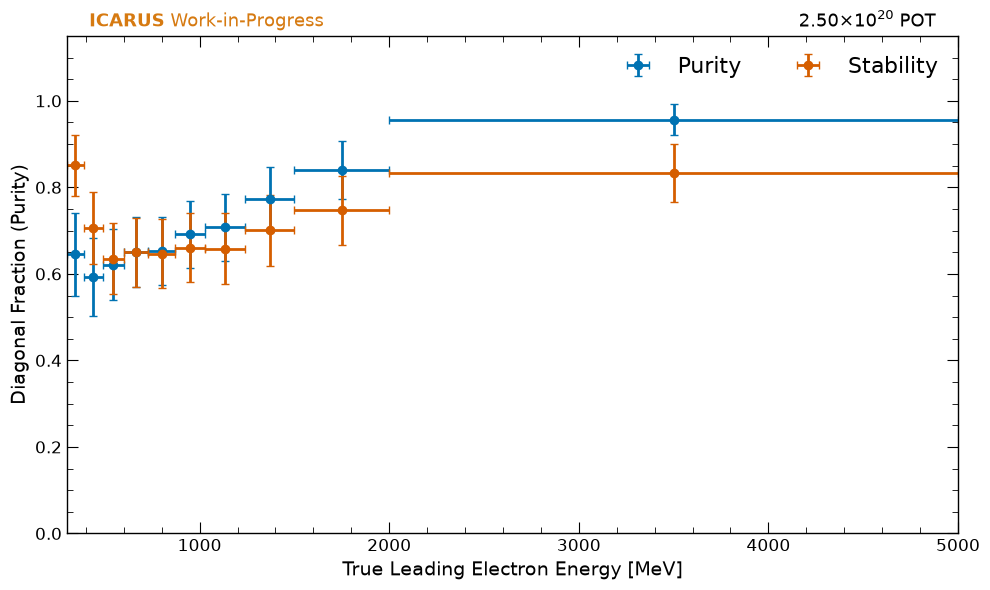

In [37]:
with open('/nashome/m/micarrig/icarus/nuESpine/medulla/plots_v30/selection/plot_true_vs_reco_leading_electron_energy.pkl', 'rb') as f:
    fig = pickle.load(f)

# Per-true-bin purity from the true-vs-reco 2D figure loaded above.
# QuadMesh array is (ny=true rows, nx=reco cols); X=reco, Y=true.
ax2d = fig.axes[0]
qm = ax2d.collections[0]

A = np.ma.filled(np.asarray(qm.get_array(), dtype=float), 0.0)  # (n_true, n_reco)
coords = np.asarray(qm.get_coordinates())                       # (ny+1, nx+1, 2)
if A.ndim == 1:
    ny, nx = coords.shape[0] - 1, coords.shape[1] - 1
    A = A.reshape(ny, nx)

yedges = coords[:, 0, 1]          # true-energy bin edges (rows)
row_tot = A.sum(axis=1)           # total events per true row
col_tot = A.sum(axis=0)           # total events per reco column
diag = np.diag(A)                 # diagonal (reco bin == true bin)
stability = np.divide(diag, row_tot, out=np.zeros_like(diag), where=row_tot > 0)
purity = np.divide(diag, col_tot, out=np.zeros_like(diag), where=col_tot > 0)

fig_p, ax_p = plt.subplots(figsize=(10, 6))
widths = np.diff(yedges)
ax_p.errorbar(yedges[:-1] + widths / 2, purity, xerr=widths / 2, yerr=np.sqrt(purity * (1 - purity) / row_tot),
         color='#0072B2', alpha=1.0, fmt='o', markersize=6, capsize=3, label='Purity')
ax_p.errorbar(yedges[:-1] + widths / 2, stability, xerr=widths / 2, yerr=np.sqrt(stability * (1 - stability) / row_tot),
         color='#D55E00', alpha=1.0, fmt='o', markersize=6, capsize=3, label='Stability')

# for left, w, p, n in zip(yedges[:-1], widths, purity, row_tot):
#     if n > 0:
#         ax_p.text(left + w / 2, p + 0.02, f'{p:.2f}', ha='center', va='bottom', fontsize=9)

ax_p.set_xlabel(ax2d.get_ylabel())          # true-energy axis
ax_p.set_ylabel('Diagonal Fraction (Purity)')
ax_p.set_ylim(0, 1.15)
ax_p.set_xlim(yedges[0]-0.1, yedges[-1])
ax_p.legend(loc='best', fontsize=16, framealpha=0.8, ncol=2)

stamp(ax_p, pot=2.5e20, work_in_progress=True)

plt.tight_layout()
plt.show()


/tmp/ipykernel_2896/1822258032.py:36: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


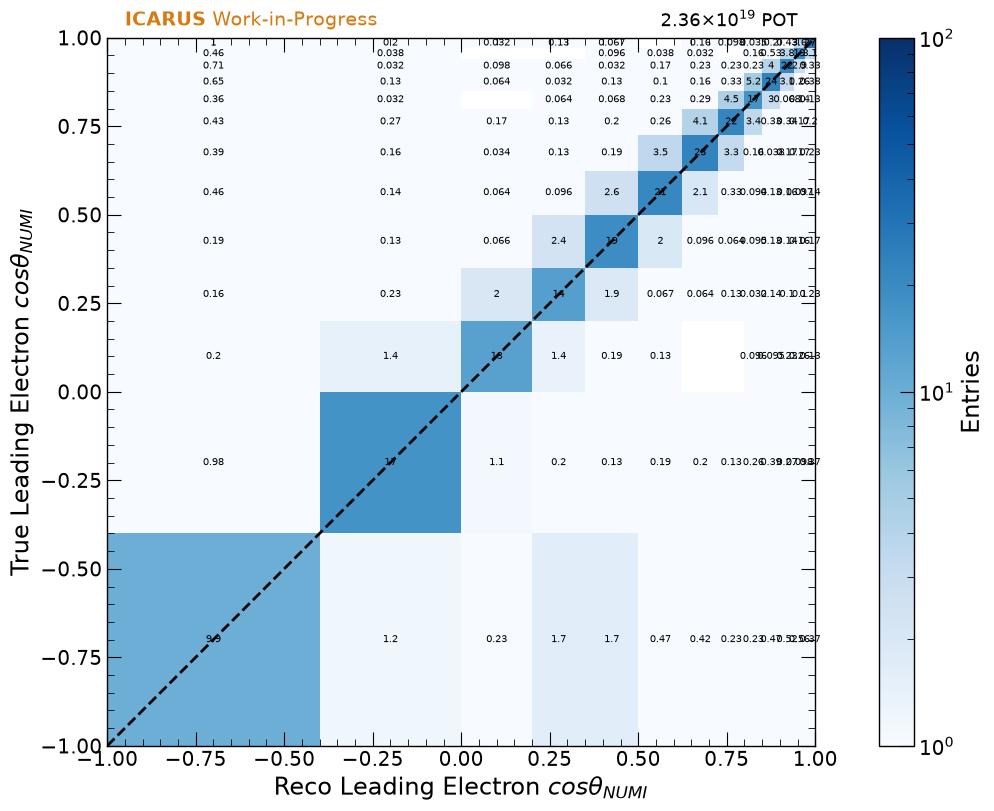

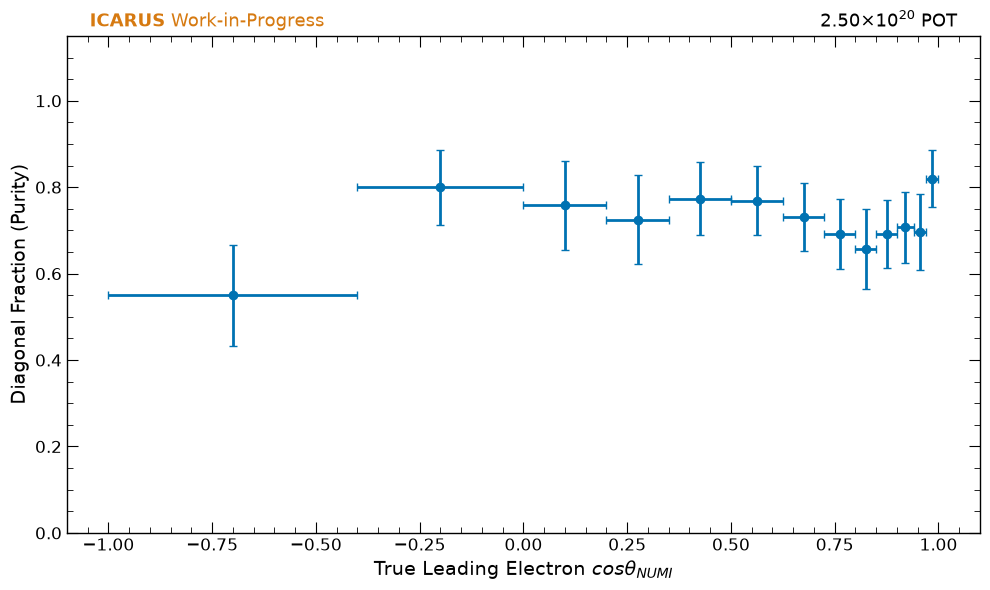

In [21]:
with open('/nashome/m/micarrig/icarus/nuESpine/medulla/plots_v30/selection/plot_true_vs_reco_leading_electron_angle.pkl', 'rb') as f:
    fig = pickle.load(f)

# Per-true-bin purity from the true-vs-reco 2D figure loaded above.
# QuadMesh array is (ny=true rows, nx=reco cols); X=reco, Y=true.
ax2d = fig.axes[0]
qm = ax2d.collections[0]

A = np.ma.filled(np.asarray(qm.get_array(), dtype=float), 0.0)  # (n_true, n_reco)
coords = np.asarray(qm.get_coordinates())                       # (ny+1, nx+1, 2)
if A.ndim == 1:
    ny, nx = coords.shape[0] - 1, coords.shape[1] - 1
    A = A.reshape(ny, nx)

yedges = coords[:, 0, 1]          # true-energy bin edges (rows)
row_tot = A.sum(axis=1)           # total events per true row
diag = np.diag(A)                 # diagonal (reco bin == true bin)
purity = np.divide(diag, row_tot, out=np.zeros_like(diag), where=row_tot > 0)

fig_p, ax_p = plt.subplots(figsize=(10, 6))
widths = np.diff(yedges)
ax_p.errorbar(yedges[:-1] + widths / 2, purity, xerr=widths / 2, yerr=np.sqrt(purity * (1 - purity) / row_tot),
         color='#0072B2', alpha=1.0, fmt='o', markersize=6, capsize=3, label='Purity')

# for left, w, p, n in zip(yedges[:-1], widths, purity, row_tot):
#     if n > 0:
#         ax_p.text(left + w / 2, p + 0.02, f'{p:.2f}', ha='center', va='bottom', fontsize=9)

ax_p.set_xlabel(ax2d.get_ylabel())          # true-energy axis
ax_p.set_ylabel('Diagonal Fraction (Purity)')
ax_p.set_ylim(0, 1.15)
# ax_p.set_xlim(yedges[0]-0.1, yedges[-1])

stamp(ax_p, pot=2.5e20, work_in_progress=True)

plt.tight_layout()
plt.show()


# Resolution by Energy

In [22]:
fin = uproot.open('/exp/icarus/data/users/micarrig/merged_v30.root:events/NuMIFull/selected')

In [23]:
reco_e = fin.arrays(['reco_leading_electron_energy'], library='np')
true_e = fin.arrays(['true_leading_electron_energy'], library='np')

/exp/icarus/app/users/micarrig/nuESpine/medulla/spineplot/.pixi/envs/default/lib/python3.14/site-packages/scipy/stats/_continuous_distns.py:11771: RuntimeWarning: overflow encountered in power
  return ((m/beta)**m * np.exp(-beta**2 / 2.0) *
/exp/icarus/app/users/micarrig/nuESpine/medulla/spineplot/.pixi/envs/default/lib/python3.14/site-packages/scipy/stats/_continuous_distns.py:11771: RuntimeWarning: invalid value encountered in multiply
  return ((m/beta)**m * np.exp(-beta**2 / 2.0) *
/tmp/ipykernel_2896/3913646108.py:101: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


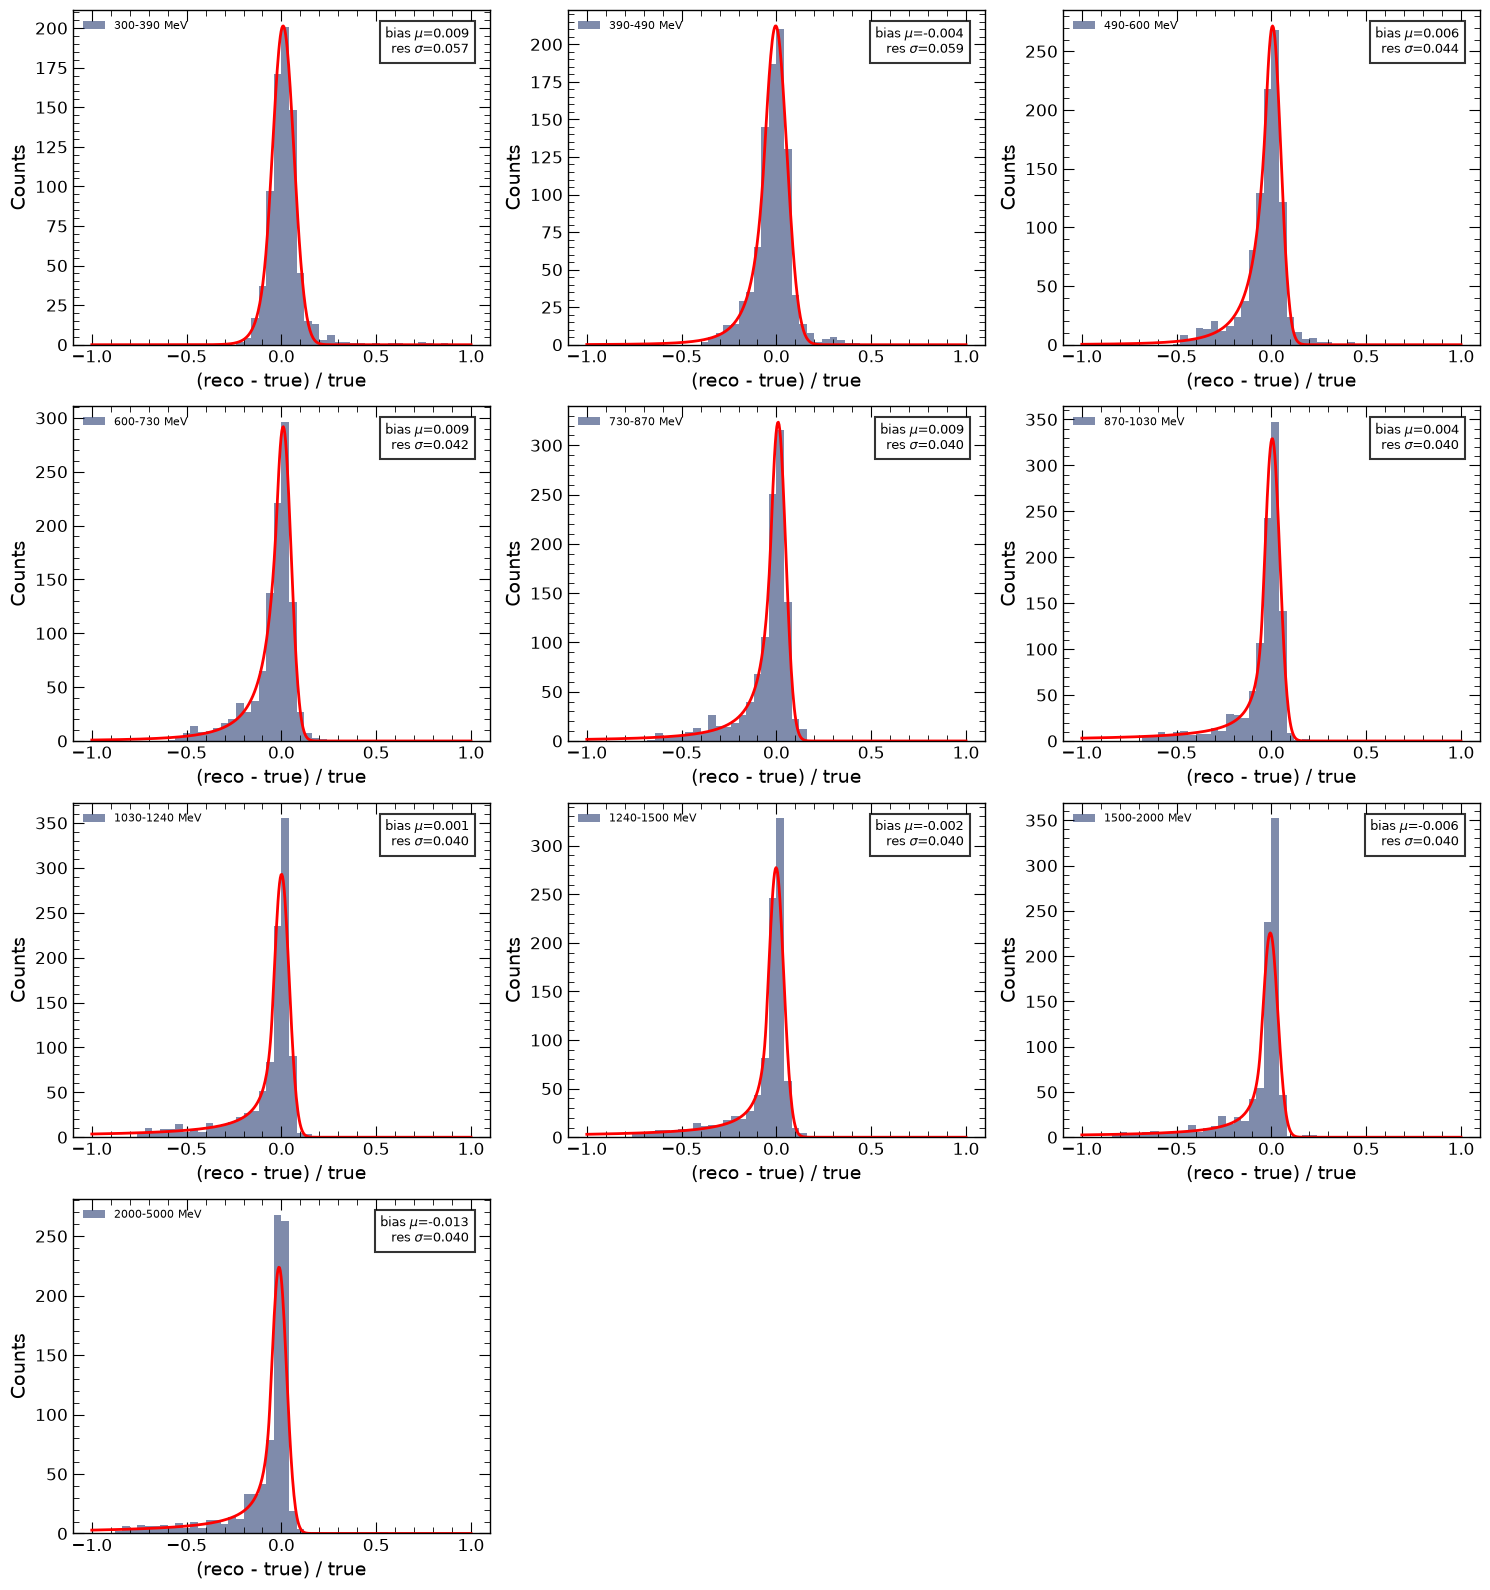

In [40]:
bins = [300, 390, 490, 600, 730, 870, 1030, 1240, 1500, 2000, 5000]


# Crystal Ball fit with an explicit bin width (each true-energy bin has its own)
def cb_fit_bw(x, N, beta, m, mu, sigma, bw):
    return N * bw * crystalball.pdf(x, beta, m, loc=mu, scale=sigma)


# per-true-bin results (of the fractional residual (reco - true)/true)
true_bin_centers = []
res_mu = []        # bias  = mean of (reco - true)/true
res_sigma = []     # resolution = width of (reco - true)/true
res_sigma_err = []

ncols = 3
nrows = int(np.ceil((len(bins) - 1) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

true_vals = true_e['true_leading_electron_energy']
reco_vals = reco_e['reco_leading_electron_energy']

for b in range(len(bins) - 1):
    ax = axes[b]

    mask = (true_vals >= bins[b]) & (true_vals < bins[b + 1])

    # fractional residual: width of this is the detector resolution
    resid = (reco_vals[mask] - true_vals[mask]) / true_vals[mask]
    resid = resid[np.isfinite(resid)]

    # histogram the residual for this true-energy bin
    counts, edges = np.histogram(resid, bins=50, range=(-1.0, 1.0))
    bw = edges[1] - edges[0]
    centers_b = 0.5 * (edges[:-1] + edges[1:])

    ax.bar(centers_b, counts, width=bw, alpha=0.5,
           label=f'{bins[b]}-{bins[b + 1]} MeV')

    # fit only non-empty bins
    sel = counts > 0
    xdata = centers_b[sel]
    ydata = counts[sel]
    sig_y = np.sqrt(ydata)

    # data-driven initial guesses
    mu0 = np.average(centers_b, weights=counts)
    sig0 = np.sqrt(np.average((centers_b - mu0) ** 2, weights=counts))
    p0_b = [counts.sum(), 1.5, 3, mu0, sig0]
    bounds_b = (
        [1, 0.5, 1.1, -1.0, bw],
        [1e12, 50, 200, 1.0, 2.0],
    )

    try:
        popt, pcov = curve_fit(
            lambda x, N, beta, m, mu, sigma: cb_fit_bw(x, N, beta, m, mu, sigma, bw),
            xdata,
            ydata,
            p0=p0_b,
            bounds=bounds_b,
            sigma=sig_y,
            absolute_sigma=True,
            maxfev=100000,
        )
        perr = np.sqrt(np.diag(pcov))

        xfit = np.linspace(edges[0], edges[-1], 500)
        ax.plot(xfit, cb_fit_bw(xfit, *popt, bw), 'r-', lw=2)

        mu_fit, sigma_fit, sigma_err = popt[3], popt[4], perr[4]

        true_bin_centers.append(0.5 * (bins[b] + bins[b + 1]))
        res_mu.append(mu_fit)
        res_sigma.append(sigma_fit)
        res_sigma_err.append(sigma_err)

        ax.text(
            0.95, 0.95,
            f"bias $\\mu$={mu_fit:.3f}\nres $\\sigma$={sigma_fit:.3f}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.8),
        )
    except RuntimeError:
        ax.text(0.5, 0.5, 'fit failed', transform=ax.transAxes,
                ha='center', va='center', color='red')

    ax.set_xlabel('(reco - true) / true')
    ax.set_ylabel('Counts')
    ax.legend(fontsize=8)

# hide any unused subplot panels
for j in range(len(bins) - 1, len(axes)):
    axes[j].set_visible(False)

true_bin_centers = np.array(true_bin_centers)
res_mu = np.array(res_mu)
res_sigma = np.array(res_sigma)
res_sigma_err = np.array(res_sigma_err)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2896/2919737558.py:102: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


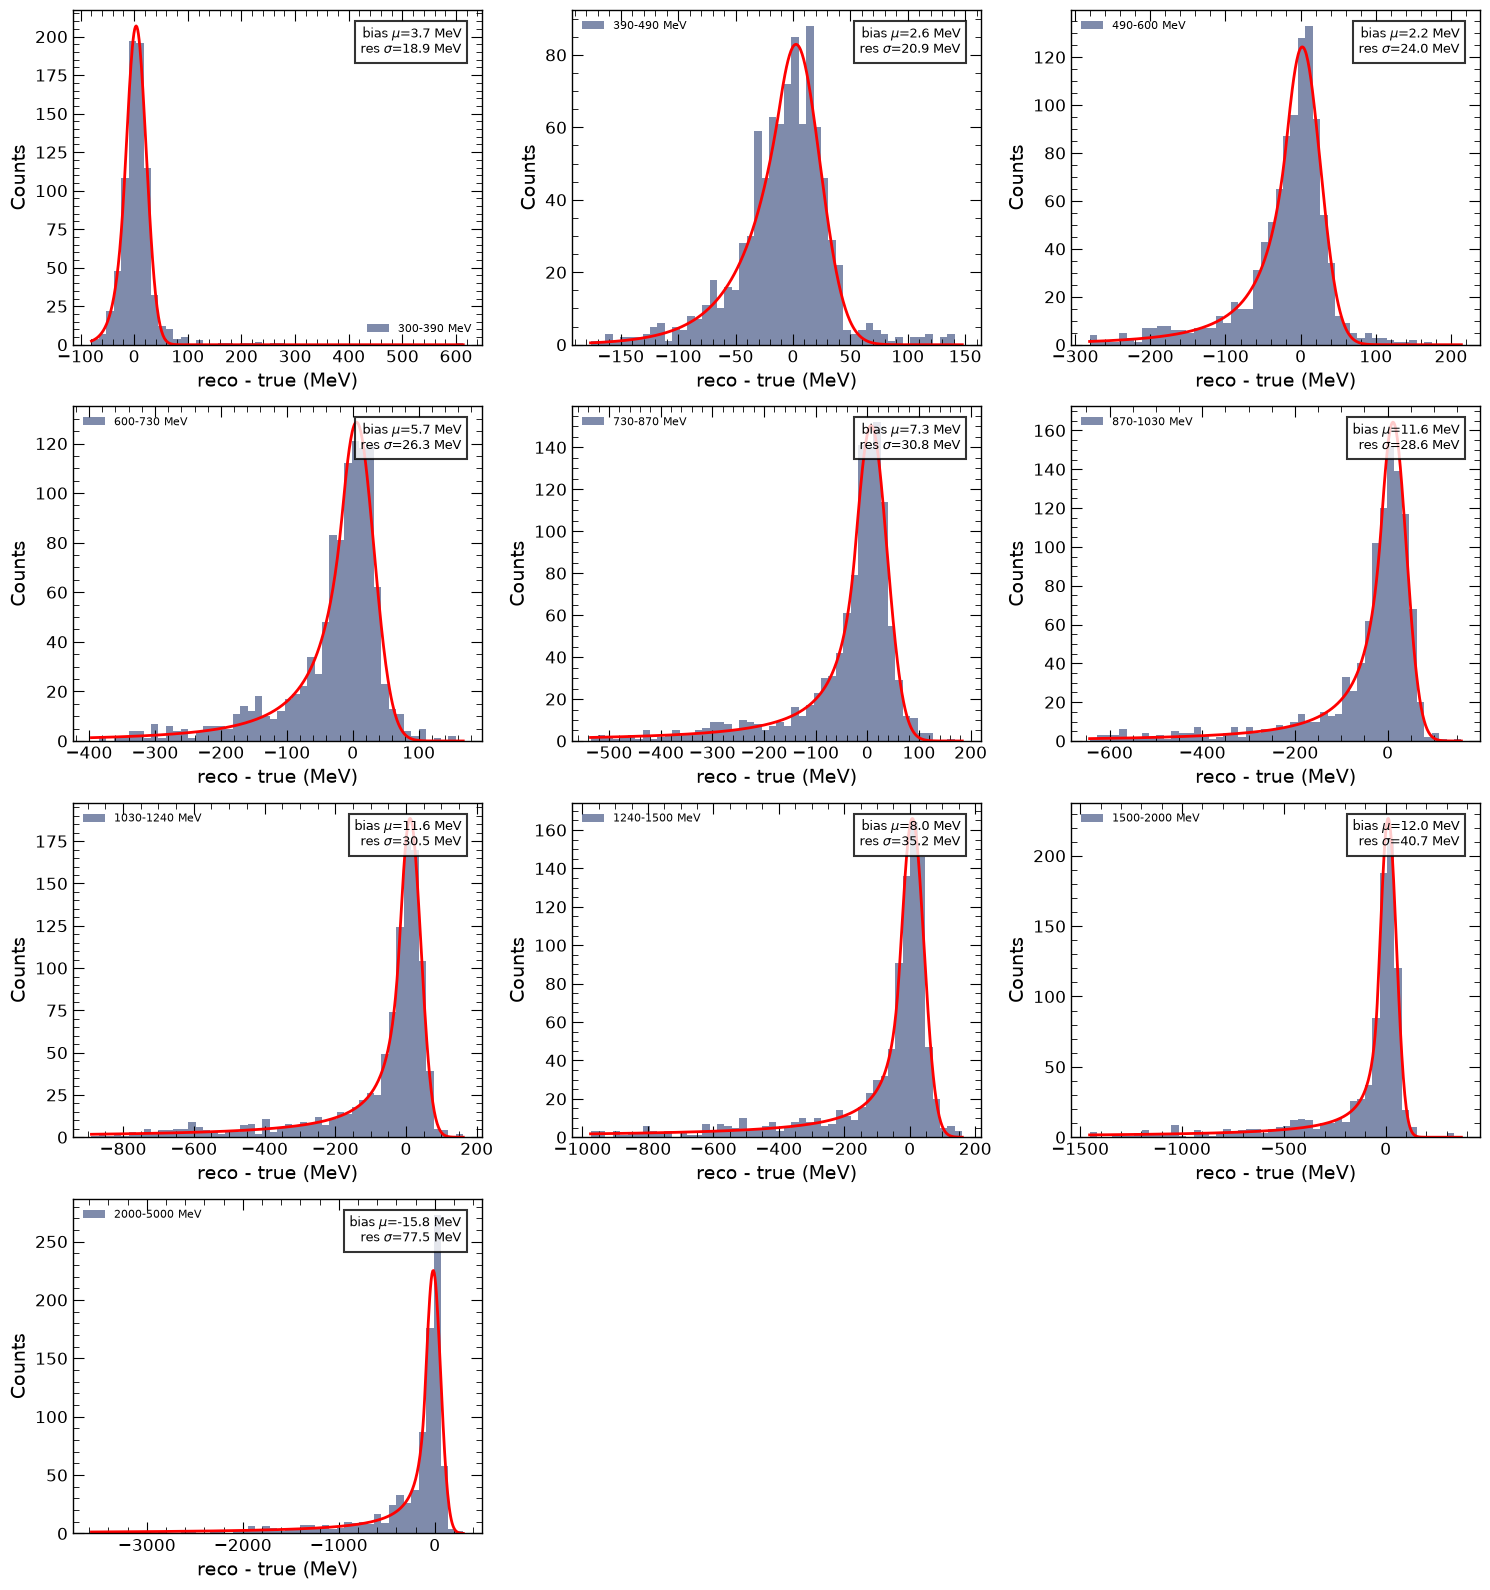

In [35]:
bins = [300, 390, 490, 600, 730, 870, 1030, 1240, 1500, 2000, 5000]


# Crystal Ball fit with an explicit bin width (each true-energy bin has its own)
def cb_fit_bw(x, N, beta, m, mu, sigma, bw):
    return N * bw * crystalball.pdf(x, beta, m, loc=mu, scale=sigma)


# per-true-bin results (of the absolute residual reco - true, in MeV)
true_bin_centers = []
res_mu = []        # bias  = mean of (reco - true)  [MeV]
res_sigma = []     # resolution = width of (reco - true)  [MeV]
res_sigma_err = []

ncols = 3
nrows = int(np.ceil((len(bins) - 1) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

true_vals = true_e['true_leading_electron_energy']
reco_vals = reco_e['reco_leading_electron_energy']

for b in range(len(bins) - 1):
    ax = axes[b]

    mask = (true_vals >= bins[b]) & (true_vals < bins[b + 1])

    # absolute residual in MeV: width of this is the detector resolution
    resid = reco_vals[mask] - true_vals[mask]
    resid = resid[np.isfinite(resid)]

    # histogram the residual, clipping extreme tails so the range adapts per bin
    lo_r, hi_r = np.percentile(resid, [0.1, 99.5])
    counts, edges = np.histogram(resid, bins=50, range=(lo_r, hi_r))
    bw = edges[1] - edges[0]
    centers_b = 0.5 * (edges[:-1] + edges[1:])

    ax.bar(centers_b, counts, width=bw, alpha=0.5,
           label=f'{bins[b]}-{bins[b + 1]} MeV')

    # fit only non-empty bins
    sel = counts > 0
    xdata = centers_b[sel]
    ydata = counts[sel]
    sig_y = np.sqrt(ydata)

    # data-driven initial guesses
    mu0 = np.average(centers_b, weights=counts)
    sig0 = np.sqrt(np.average((centers_b - mu0) ** 2, weights=counts))
    p0_b = [counts.sum(), 1.5, 3, mu0, sig0]
    bounds_b = (
        [1, 0.5, 1.1, lo_r, bw],
        [1e12, 50, 200, hi_r, hi_r - lo_r],
    )

    try:
        popt, pcov = curve_fit(
            lambda x, N, beta, m, mu, sigma: cb_fit_bw(x, N, beta, m, mu, sigma, bw),
            xdata,
            ydata,
            p0=p0_b,
            bounds=bounds_b,
            sigma=sig_y,
            absolute_sigma=True,
            maxfev=100000,
        )
        perr = np.sqrt(np.diag(pcov))

        xfit = np.linspace(edges[0], edges[-1], 500)
        ax.plot(xfit, cb_fit_bw(xfit, *popt, bw), 'r-', lw=2)

        mu_fit, sigma_fit, sigma_err = popt[3], popt[4], perr[4]

        true_bin_centers.append(0.5 * (bins[b] + bins[b + 1]))
        res_mu.append(mu_fit)
        res_sigma.append(sigma_fit)
        res_sigma_err.append(sigma_err)

        ax.text(
            0.95, 0.95,
            f"bias $\\mu$={mu_fit:.1f} MeV\nres $\\sigma$={sigma_fit:.1f} MeV",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.8),
        )
    except RuntimeError:
        ax.text(0.5, 0.5, 'fit failed', transform=ax.transAxes,
                ha='center', va='center', color='red')

    ax.set_xlabel('reco - true (MeV)')
    ax.set_ylabel('Counts')
    ax.legend(fontsize=8)

# hide any unused subplot panels
for j in range(len(bins) - 1, len(axes)):
    axes[j].set_visible(False)

true_bin_centers = np.array(true_bin_centers)
res_mu = np.array(res_mu)
res_sigma = np.array(res_sigma)
res_sigma_err = np.array(res_sigma_err)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2896/2215033674.py:23: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


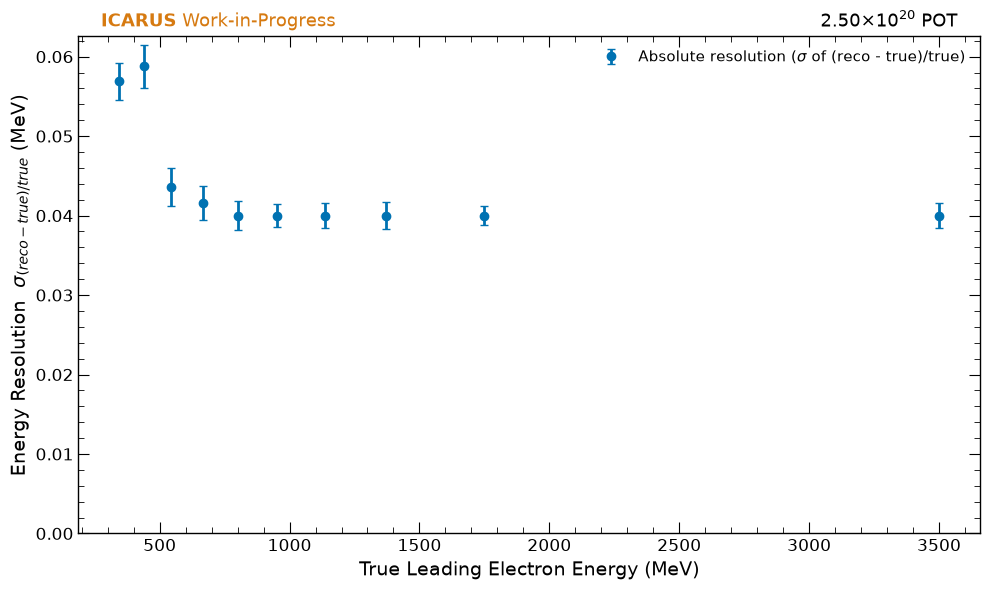

In [43]:
# --------------------------------------------------
# Resolution vs true energy
# --------------------------------------------------
# res_sigma is the width of (reco - true) in MeV -> the absolute energy resolution.

fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    true_bin_centers,
    res_sigma,
    yerr=res_sigma_err,
    color='#0072B2', fmt='o', markersize=6, capsize=3,
    label='Absolute resolution ($\\sigma$ of (reco - true)/true)',
)

ax.set_xlabel('True Leading Electron Energy (MeV)')
ax.set_ylabel('Energy Resolution  $\\sigma_{(reco-true)/true}$ (MeV)')
ax.set_ylim(bottom=0)

stamp(ax, pot=2.5e20, work_in_progress=True)

ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_2896/3080310633.py:35: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


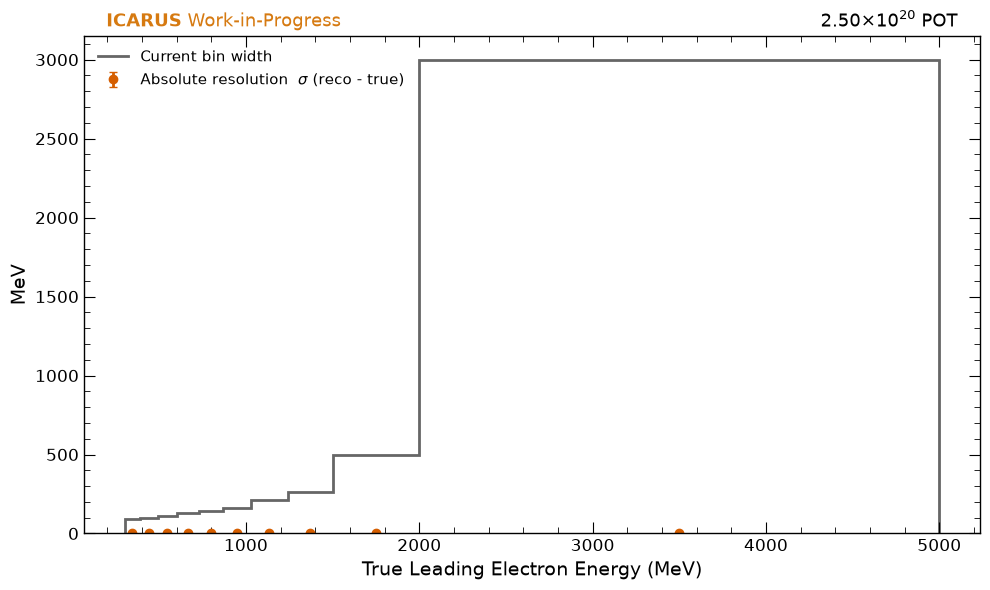

bin [MeV]            width   sigma_abs   width/sigma
   300-390           90        0.1    1582.01
   390-490          100        0.1    1701.68
   490-600          110        0.0    2520.63
   600-730          130        0.0    3124.93
   730-870          140        0.0    3500.00
   870-1030         160        0.0    4000.00
  1030-1240         210        0.0    5250.00
  1240-1500         260        0.0    6500.00
  1500-2000         500        0.0   12500.00
  2000-5000        3000        0.0   75000.00


In [41]:
# --------------------------------------------------
# Absolute resolution vs current bin widths
# --------------------------------------------------
# A bin is resolution-limited when its width is <~ the local absolute
# resolution sigma_abs (width of reco - true). Narrower bins mostly migrate events.

bins_arr = np.array(bins, dtype=float)
bin_widths = np.diff(bins_arr)
bin_centers = 0.5 * (bins_arr[:-1] + bins_arr[1:])

# absolute resolution is already in MeV from the fit
sigma_abs = res_sigma
sigma_abs_err = res_sigma_err

fig, ax = plt.subplots(figsize=(10, 6))

# current bin widths as a step, so each bin's width is visible vs its energy
ax.stairs(bin_widths, bins_arr, color='0.4', fill=False, lw=2,
          label='Current bin width')

# absolute resolution at the measured true-bin centers
ax.errorbar(
    true_bin_centers, sigma_abs, yerr=sigma_abs_err,
    color='#D55E00', fmt='o', markersize=6, capsize=3,
    label='Absolute resolution  $\\sigma$ (reco - true)',
)

ax.set_xlabel('True Leading Electron Energy (MeV)')
ax.set_ylabel('MeV')
ax.set_ylim(bottom=0)

stamp(ax, pot=2.5e20, work_in_progress=True)

ax.legend()
plt.tight_layout()
plt.show()

# flag bins narrower than the local resolution
print("bin [MeV]            width   sigma_abs   width/sigma")
for lo, hi, w, c in zip(bins_arr[:-1], bins_arr[1:], bin_widths, bin_centers):
    # nearest measured true-bin center
    i = int(np.argmin(np.abs(true_bin_centers - c)))
    s = sigma_abs[i]
    flag = "  <-- below resolution" if w < s else ""
    print(f"{lo:6.0f}-{hi:<6.0f}    {w:6.0f}   {s:8.1f}   {w / s:8.2f}{flag}")